# Part A — Illumination Correction preprocessing pipeline

A classical, deterministic preprocessing pipeline for cervical colposcopy
images. **All QI-SABP-specific machinery (quantum-inspired fused saliency,
soft mask, edge-aware bit allocation, dithered quantization, YCbCr 4:2:0
subsample, bilateral post-filter, histogram match) has been removed.** This
notebook now contains a clean, pixel-domain Illumination Correction
pipeline.

## Pipeline overview

The pipeline corrects the per-frame illumination artefacts that the
colposcope + speculum introduce: specular glare, vignetting, uneven
field-of-view (FOV) shading and colour casts. The output is a uint8 RGB
image of the same shape as the input — no bit allocation, no compression.

* Step 1 — Unsharp-mask sharpen (carried over from Step 1).
* Step A — Field-of-view (FOV) mask (largest bright connected region,
  convex-hull filled so frame-edge notches do not leak into the FOV).
* Step B — Specular-glare detection and inpainting (bright + low-saturation
  + small-blob test → Telea inpaint). Acetowhite epithelium is explicitly
  NOT treated as glare (the blob-area filter rejects large bright blobs).
* Step C — Background illumination estimation (large-kernel morphological
  opening on the V channel + large Gaussian blur).
* Step D — Divisive illumination normalization
  `(V - dark_floor) / (bg - dark_floor) * target_luma`. The gain map is
  smoothed to avoid ringing at the FOV boundary. Outside the FOV the
  original pixels are kept.
* Step E — CLAHE on the L channel of LAB (local contrast normalization).
* Step F — Gray-world white balance (per-channel trimmed-mean scaling
  inside the FOV).

## Output

The pipeline returns a uint8 RGB image of the same shape as the input.
Because it operates in the pixel domain only (no bit allocation, no
quantization, no chroma subsample), the **Luma bits metric (m11) is
constant at 8.0 bits/px** for every frame. This is by design: the
pipeline does not compress, so the analytic bit rate is the full uint8
rate.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other (only
  IlluminationCorrection vs Identity, for descriptive purposes).
* It does NOT demonstrate a clinical benefit on this single patient.

In [1]:
# ============================================================
# Cell 1.1 -- Combined imports & global setup
# ============================================================
import os, sys, glob, time, json, math, random, warnings, platform
from collections import defaultdict
from pathlib import Path

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import ListedColormap

import pandas as pd
from scipy import ndimage, stats
from scipy.ndimage import gaussian_filter

# scikit-image is needed for SSIM, CIE76 dE, LAB conversion and Frangi.
try:
    from skimage.metrics import structural_similarity as _ssim_fn
    from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn
    from skimage.filters import frangi as _frangi_fn
    _SKIMAGE_OK = True
except ImportError:
    _SKIMAGE_OK = False
    print("[warn] scikit-image not available -- SSIM/dE76/Frangi will be skipped.")

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for CSV / JSON artefacts.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"Illumination Correction Validation Pipeline -- Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")

Illumination Correction Validation Pipeline -- Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 -- Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"
CLASSES        = ["invasive cancer"]

# ---- Sharpen (Step 1, shared across the suite) ----
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- Step A: FOV mask ----
FOV_THRESHOLD       = 15     # gray threshold for FOV (the speculum ring is brighter)
FOV_FILL_NOTCHES     = True   # convex-hull fill of frame-edge notches

# ---- Step B: Specular glare detection + inpainting ----
# Glare = bright AND low-saturation AND small blob. The blob-area filter
# is important: acetowhite epithelium is also bright+low-saturation but
# covers a large region. Pure specular glare is a small dot.
USE_GLARE_REMOVAL    = True
GLARE_V_THR          = 250    # V >= 250 (very bright)
GLARE_S_THR          = 25     # S <= 25  (low saturation)
GLARE_MAX_BLOB_FRAC  = 0.01   # reject glare blobs > 1% of FOV area
GLARE_INPAINT_RADIUS = 5      # cv2.inpaint radius

# ---- Step C: Background illumination estimation ----
# Large-kernel morphological opening on the V channel -> rolling-ball
# like background. Smoothed with a large Gaussian to remove residual
# structure.
BG_KERNEL_SIZE       = 51     # morphological opening kernel (px)
BG_SIGMA             = 30.0   # Gaussian blur sigma (px)

# ---- Step D: Divisive illumination normalization ----
#   corrected = (V - dark_floor) / (bg - dark_floor) * target_luma
# The gain map is smoothed to avoid ringing at the FOV boundary.
USE_DIVISIVE_NORM    = True
DARK_FLOOR           = 5.0    # subtracted before division (avoids /0)
TARGET_LUMA          = 128.0  # target mean V after normalization

# ---- Step E: CLAHE on L channel of LAB ----
USE_CLAHE            = True
CLAHE_CLIP_LIMIT     = 2.0
CLAHE_TILE_SIZE      = 8      # tile grid size (px)

# ---- Step F: Gray-world white balance ----
USE_GRAY_WORLD       = True
GRAY_WORLD_PCT       = 90     # trim to central 90% before per-channel mean

# ---- Validation batch ----
N_PER_CLASS_VALIDATE  = 5
SUBSET_PER_CLASS      = None

SYNTHETIC_MODE = False   # set later by the loader

# ---- Print summary ----
print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen={APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})")
print(f"  FOV: threshold={FOV_THRESHOLD}, fill_notches={FOV_FILL_NOTCHES}")
print(f"  glare: V>{GLARE_V_THR}, S<{GLARE_S_THR}, max_blob={GLARE_MAX_BLOB_FRAC}, "
      f"radius={GLARE_INPAINT_RADIUS}")
print(f"  background: kernel={BG_KERNEL_SIZE}, sigma={BG_SIGMA}")
print(f"  divisive_norm={USE_DIVISIVE_NORM} (dark_floor={DARK_FLOOR}, "
      f"target_luma={TARGET_LUMA})")
print(f"  CLAHE={USE_CLAHE} (clip={CLAHE_CLIP_LIMIT}, tile={CLAHE_TILE_SIZE})")
print(f"  gray_world={USE_GRAY_WORLD} (pct={GRAY_WORLD_PCT})")
print(f"  validation batch = {N_PER_CLASS_VALIDATE} imgs/class")
print(f"  NOTE: the pipeline operates in the pixel domain only -- the Luma bits")
print(f"        metric (m11) is constant at 8.0 bits/px for every frame.")

Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen=True (amount=0.8, ksize=5)
  FOV: threshold=15, fill_notches=True
  glare: V>250, S<25, max_blob=0.01, radius=5
  background: kernel=51, sigma=30.0
  divisive_norm=True (dark_floor=5.0, target_luma=128.0)
  CLAHE=True (clip=2.0, tile=8)
  gray_world=True (pct=90)
  validation batch = 5 imgs/class
  NOTE: the pipeline operates in the pixel domain only -- the Luma bits
        metric (m11) is constant at 8.0 bits/px for every frame.


In [3]:
# ============================================================
# Cell 1.3 -- Sharpen + preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """BGR -> RGB -> resize -> (optional) sharpen. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 sharpen_it=APPLY_SHARPEN, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize,
    optionally sharpen. Case-insensitive dedupe by filename."""
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask."""
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (sharpen =", APPLY_SHARPEN, ")")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = sharpen(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")

Loading dataset ...  (sharpen = True )
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


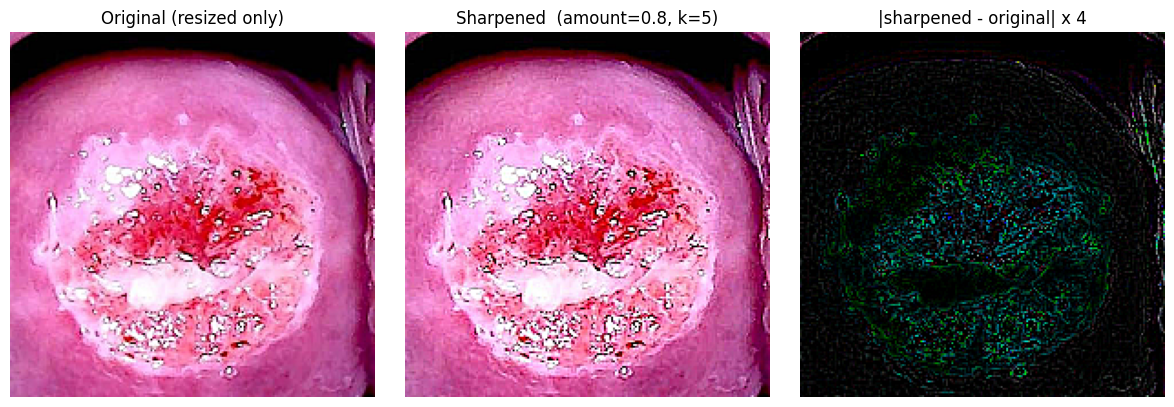

In [4]:
# ============================================================
# Cell 1.4 -- Sharpen before/after visualisation
# ============================================================
def show_sharpen_effect(img_path=None, img_rgb=None):
    """Show original / sharpened / high-pass diff for a single image."""
    if img_rgb is None:
        raw_bgr = cv2.imread(img_path)
        if raw_bgr is None:
            print("Could not read", img_path); return
        raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        raw_resized = cv2.resize(raw_rgb, (IMG_SIZE, IMG_SIZE))
    else:
        raw_resized = img_rgb
    sharpened = sharpen(raw_resized)
    diff = np.clip(sharpened.astype(np.int16) - raw_resized.astype(np.int16),
                   0, 255).astype(np.uint8)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(raw_resized);    ax[0].set_title("Original (resized only)")
    ax[0].axis("off")
    ax[1].imshow(sharpened);      ax[1].set_title(
        f"Sharpened  (amount={SHARPEN_AMOUNT}, k={SHARPEN_KSIZE})")
    ax[1].axis("off")
    ax[2].imshow(diff * 4, cmap="gray")
    ax[2].set_title("|sharpened - original| x 4")
    ax[2].axis("off")
    plt.tight_layout(); plt.show()


if len(X_raw) > 0:
    show_sharpen_effect(img_rgb=X_raw[0])
else:
    demo = np.random.RandomState(SEED).randint(40, 200, (200, 200, 3), dtype=np.uint8)
    demo[60:140, 60:140] = np.random.RandomState(SEED+1).randint(160, 255, (80, 80, 3), dtype=np.uint8)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(demo);               ax[0].set_title("Original");       ax[0].axis("off")
    ax[1].imshow(sharpen(demo));      ax[1].set_title("Sharpened");      ax[1].axis("off")
    plt.tight_layout(); plt.show()

In [5]:
# ============================================================
# Cell 2.1 -- Illumination Correction pipeline (RGB)
#
# Output type: this pipeline returns a uint8 RGB image of the same shape
# as the input. It operates in the pixel domain only -- no bit allocation,
# no quantization, no chroma subsampling. The Luma bits metric (m11) is
# therefore constant at 8.0 bits/px for every frame.
#
# Steps:
#   A. FOV mask (largest bright connected region, convex-hull filled)
#   B. Specular-glare detection + Telea inpaint (small bright low-sat blobs)
#   C. Background illumination estimation (large morphological opening + Gaussian)
#   D. Divisive illumination normalization
#   E. CLAHE on L channel of LAB
#   F. Gray-world white balance (per-channel trimmed-mean scaling)
# ============================================================

def compute_fov_mask(img_rgb, thr=None, fill_notches=None):
    """Field-of-view mask: largest bright connected region, holes filled,
    optionally convex-hull filled to remove frame-edge notches."""
    if thr is None:          thr = FOV_THRESHOLD
    if fill_notches is None: fill_notches = FOV_FILL_NOTCHES
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    if not fill_notches:
        return fov
    ys, xs = np.where(fov)
    if len(ys) < 3:
        return fov
    pts = np.stack([xs, ys], axis=1).astype(np.int32)
    hull = cv2.convexHull(pts)
    hull_mask = np.zeros(g.shape, dtype=np.uint8)
    cv2.fillConvexPoly(hull_mask, hull, 1)
    hull_mask = hull_mask.astype(bool)
    x0, x1 = int(xs.min()), int(xs.max())
    y0, y1 = int(ys.min()), int(ys.max())
    bbox = np.zeros(g.shape, dtype=bool)
    bbox[y0:y1+1, x0:x1+1] = True
    hull_mask = hull_mask & bbox
    ksize = 11
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                  cv2.MORPH_CLOSE, kernel).astype(bool)
    return fov | hull_mask


def detect_glare(img_rgb, fov_mask,
                 v_thr=None, s_thr=None, max_blob_frac=None):
    """Specular glare mask: bright AND low-saturation AND small blob.

    The blob-area filter is critical: acetowhite epithelium is also
    bright + low-saturation but covers a large region. Pure specular
    glare is a small dot. Components whose area exceeds max_blob_frac of
    the FOV are rejected as acetowhite tissue.
    """
    if v_thr is None:          v_thr = GLARE_V_THR
    if s_thr is None:          s_thr = GLARE_S_THR
    if max_blob_frac is None:  max_blob_frac = GLARE_MAX_BLOB_FRAC
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    cand = ((hsv[..., 2] >= v_thr) &
            (hsv[..., 1] <= s_thr) &
            fov_mask).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(cand)
    if n <= 1:
        return np.zeros_like(cand, dtype=bool)
    out = np.zeros_like(cand, dtype=bool)
    fov_area = max(float(fov_mask.sum()), 1.0)
    for k in range(1, n):
        area = float(st[k, cv2.CC_STAT_AREA])
        if area / fov_area <= max_blob_frac:
            out |= (lab == k)
    # Dilate slightly so inpaint covers the glare halo
    if out.any():
        out = cv2.dilate(out.astype(np.uint8),
                          cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))) > 0
    return out


def inpaint_glare(img_rgb, glare_mask, radius=None):
    """Telea inpainting of specular glare pixels."""
    if radius is None: radius = GLARE_INPAINT_RADIUS
    if not glare_mask.any():
        return img_rgb.copy()
    return cv2.inpaint(img_rgb, glare_mask.astype(np.uint8),
                       radius, cv2.INPAINT_TELEA)


def estimate_background(img_rgb, fov_mask,
                        kernel_size=None, sigma=None):
    """Background illumination via morphological opening on the V channel,
    smoothed with a large Gaussian. The FOV exterior is filled with the
    FOV-mean V first, so the morphological operator does not pick up
    black frame pixels."""
    if kernel_size is None: kernel_size = BG_KERNEL_SIZE
    if sigma is None:       sigma = BG_SIGMA
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    v = hsv[..., 2].astype(np.float32)
    v_masked = v.copy()
    if fov_mask.any():
        v_masked[~fov_mask] = float(v[fov_mask].mean())
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,
                                        (kernel_size, kernel_size))
    bg = cv2.morphologyEx(v_masked, cv2.MORPH_OPEN, kernel)
    bg = cv2.GaussianBlur(bg, (0, 0), sigma)
    if fov_mask.any():
        bg[~fov_mask] = float(v[fov_mask].mean())
    return bg


def divisive_normalize(img_rgb, fov_mask, bg,
                       dark_floor=None, target_luma=None):
    """Divisive illumination normalization:
        corrected = (img - dark) / (bg - dark) * (target - dark) + dark
    Applied uniformly across RGB channels using the V-channel gain map.
    The gain is smoothed (Gaussian sigma=2) to avoid ringing at the FOV
    boundary. Outside the FOV the original pixels are kept.
    """
    if dark_floor is None:  dark_floor = DARK_FLOOR
    if target_luma is None: target_luma = TARGET_LUMA
    f = np.asarray(fov_mask, dtype=bool)
    img_f = img_rgb.astype(np.float32)
    denom = np.maximum(bg - dark_floor, 1e-3)
    gain = (target_luma - dark_floor) / denom
    # Cap gain to a sane range to avoid blow-up in dark corners
    gain = np.clip(gain, 0.5, 4.0)
    # Smooth the gain map (Gaussian) so the correction is spatially smooth
    gain = cv2.GaussianBlur(gain, (0, 0), 2.0)
    out = (img_f - dark_floor) * gain[..., None] + dark_floor
    out = np.clip(out, 0, 255).astype(np.uint8)
    out[~f] = img_rgb[~f]
    return out


def clahe_lab(img_rgb, fov_mask,
              clip_limit=None, tile_size=None):
    """CLAHE on L channel of LAB."""
    if clip_limit is None: clip_limit = CLAHE_CLIP_LIMIT
    if tile_size is None:  tile_size = CLAHE_TILE_SIZE
    # cv2 expects LAB as uint8 with L in [0, 255].
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    L = lab[..., 0]
    clahe = cv2.createCLAHE(clipLimit=clip_limit,
                             tileGridSize=(tile_size, tile_size))
    L_eq = clahe.apply(L)
    lab[..., 0] = L_eq
    out = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    out[~fov_mask] = img_rgb[~fov_mask]
    return out


def gray_world_balance(img_rgb, fov_mask, pct=None):
    """Gray-world white balance: scale each channel so its trimmed mean
    (inside the FOV) matches the average of all channels."""
    if pct is None: pct = GRAY_WORLD_PCT
    if not fov_mask.any():
        return img_rgb.copy()
    img_f = img_rgb.astype(np.float32)
    lo_p = (100 - pct) / 2
    hi_p = 100 - lo_p
    means = []
    for c in range(3):
        ch_in = img_f[..., c][fov_mask]
        lo = np.percentile(ch_in, lo_p)
        hi = np.percentile(ch_in, hi_p)
        keep = (ch_in >= lo) & (ch_in <= hi)
        if keep.sum() < 1:
            means.append(float(ch_in.mean()))
        else:
            means.append(float(ch_in[keep].mean()))
    target = float(np.mean(means))
    scales = np.array([target / max(m, 1e-3) for m in means], dtype=np.float32)
    out = np.clip(img_f * scales[None, None, :], 0, 255).astype(np.uint8)
    out[~fov_mask] = img_rgb[~fov_mask]
    return out


def illumination_correction(img_rgb, return_artefacts=True, fov_mask=None):
    """Full Illumination Correction preprocessing pipeline (uint8 RGB in/out).

    Steps:
      A. FOV mask
      B. Specular-glare detection + inpaint
      C. Background illumination estimation
      D. Divisive illumination normalization
      E. CLAHE on L channel
      F. Gray-world white balance

    If `return_artefacts=True`, returns a dict with the intermediate images
    and masks; otherwise returns only the final processed image.
    """
    # Step A: FOV mask
    fov = compute_fov_mask(img_rgb) if fov_mask is None else np.asarray(fov_mask, dtype=bool)
    # Step B: Glare detection and inpainting
    if USE_GLARE_REMOVAL:
        glare = detect_glare(img_rgb, fov)
        img_deglared = inpaint_glare(img_rgb, glare)
    else:
        glare = np.zeros_like(fov)
        img_deglared = img_rgb.copy()
    # Step C: Background illumination estimation
    bg = estimate_background(img_deglared, fov)
    # Step D: Divisive normalization
    if USE_DIVISIVE_NORM:
        img_norm = divisive_normalize(img_deglared, fov, bg)
    else:
        img_norm = img_deglared.copy()
    # Step E: CLAHE on L channel
    if USE_CLAHE:
        img_clahe = clahe_lab(img_norm, fov)
    else:
        img_clahe = img_norm.copy()
    # Step F: Gray-world white balance
    if USE_GRAY_WORLD:
        img_final = gray_world_balance(img_clahe, fov)
    else:
        img_final = img_clahe.copy()
    if return_artefacts:
        return {
            'img_original':  img_rgb,
            'fov_mask':       fov,
            'glare_mask':     glare,
            'img_deglared':   img_deglared,
            'background':     bg,
            'img_normalized': img_norm,
            'img_clahe':      img_clahe,
            'img_processed':  img_final,
        }
    return img_final


# Quick smoke-test on the first image
if len(X_raw) > 0:
    _smoke = illumination_correction(X_raw[0], return_artefacts=False)
    assert _smoke.dtype == np.uint8 and _smoke.shape == X_raw[0].shape, \
        f"shape/dtype mismatch: {_smoke.shape} {_smoke.dtype}"
    print(f"illumination_correction smoke-test OK  |  in={X_raw[0].shape}  out={_smoke.shape}")
else:
    print("[warn] No images loaded -- skipping smoke test.")

illumination_correction smoke-test OK  |  in=(200, 200, 3)  out=(200, 200, 3)


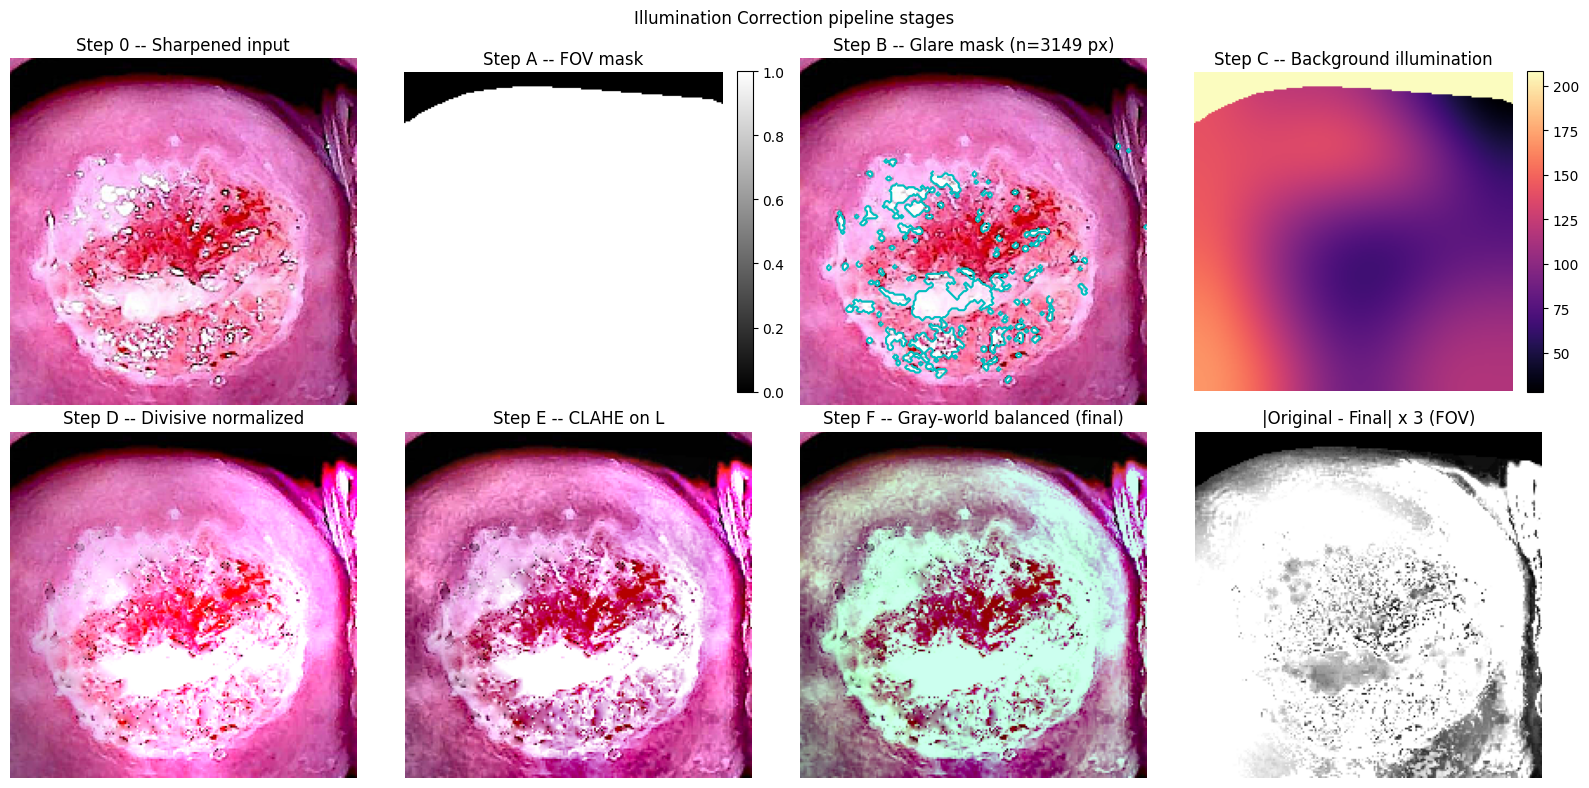

In [6]:
# ============================================================
# Cell 2.2 -- Visualise Illumination Correction stages
# ============================================================
def show_illumination_stages(rgb_image, title=""):
    """Show the eight intermediate stages of the Illumination Correction
    pipeline for a single image."""
    enc = illumination_correction(rgb_image)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.ravel()

    axes[0].imshow(enc['img_original'])
    axes[0].set_title("Step 0 -- Sharpened input")
    axes[0].axis('off')

    im_fov = axes[1].imshow(enc['fov_mask'].astype(np.float32), cmap='gray', vmin=0, vmax=1)
    axes[1].set_title("Step A -- FOV mask")
    axes[1].axis('off'); plt.colorbar(im_fov, ax=axes[1], fraction=0.046, pad=0.04)

    # Glare mask overlay on the original
    axes[2].imshow(enc['img_original'])
    if enc['glare_mask'].any():
        gm = enc['glare_mask'].astype(np.uint8)
        contours, _ = cv2.findContours(gm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for cnt in contours:
            cnt_pts = cnt.squeeze(1)
            if cnt_pts.ndim == 1:
                continue
            axes[2].plot(cnt_pts[:, 0], cnt_pts[:, 1], '-c', linewidth=1.5)
    axes[2].set_title(f"Step B -- Glare mask (n={int(enc['glare_mask'].sum())} px)")
    axes[2].axis('off')

    im_bg = axes[3].imshow(enc['background'], cmap='magma')
    axes[3].set_title("Step C -- Background illumination")
    axes[3].axis('off'); plt.colorbar(im_bg, ax=axes[3], fraction=0.046, pad=0.04)

    axes[4].imshow(enc['img_normalized'])
    axes[4].set_title("Step D -- Divisive normalized")
    axes[4].axis('off')

    axes[5].imshow(enc['img_clahe'])
    axes[5].set_title("Step E -- CLAHE on L")
    axes[5].axis('off')

    axes[6].imshow(enc['img_processed'])
    axes[6].set_title("Step F -- Gray-world balanced (final)")
    axes[6].axis('off')

    diff_rgb = np.abs(enc['img_original'].astype(np.float32) - enc['img_processed'].astype(np.float32))
    diff_gray = diff_rgb.mean(axis=-1)
    diff_gray[~enc['fov_mask']] = 0.0
    p99 = max(float(np.percentile(diff_gray[enc['fov_mask']], 99)) if enc['fov_mask'].any() else 1e-6, 1e-6)
    axes[7].imshow(np.clip(diff_gray * 3.0 / p99, 0, 1), cmap='gray', vmin=0, vmax=1)
    axes[7].set_title("|Original - Final| x 3 (FOV)")
    axes[7].axis('off')

    plt.suptitle(title or "Illumination Correction pipeline stages")
    plt.tight_layout(); plt.show()


if len(X_raw) > 0:
    show_illumination_stages(X_raw[0])
else:
    print("[warn] No images to visualise.")

# Bridge -- hand off Illumination Correction preprocessing to Step 4

Step 4 expects four variables from Steps 1-2:

| Step-4 name | Meaning                                   | Source in this notebook                       |
|-------------|-------------------------------------------|-----------------------------------------------|
| `X_base`    | (N,200,200,3) uint8 RGB, **sharpened**    | `X_raw` (sharpened by the loader)             |
| `X_raw`     | (N,200,200,3) uint8 RGB, **resize-only**  | reloaded with `sharpen_it=False`              |
| `image_ids` | unique id per image                       | sequential `img_NNNN`                          |
| `masks`     | clinician lesion masks (OPTIONAL)         | `masks_raw` from the loader                    |

We also register the technique:

* `ILLUM_DEFAULTS` -- empty dict (the pipeline uses fixed module-level
  config; no tuning on a single patient).
* `illum(img, params, seed) -> uint8 RGB image` -- wraps
  `illumination_correction(img, return_artefacts=False)`. The pipeline
  is fully deterministic; the `seed` argument is accepted for API
  symmetry with the validator but is not used.

In [7]:
# ============================================================
# Bridge -- hand off Illumination Correction to Step 4.
# ============================================================

# --- Step-2 sharpened stack becomes the validator's X_base ---
X_base = X_raw.copy()                       # sharpened, 200x200, uint8 RGB
_masks = masks_raw.copy()                   # clinician masks (synthetic in fallback)

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))],
                     dtype=object)
assert len(set(image_ids)) == len(X_base), \
    "image_ids not unique after bridge (this should never happen)"

# --- Reload the SAME images WITHOUT sharpening -> validator's X_raw ---
#     (used only as the source for the field-of-view mask)
if not SYNTHETIC_MODE:
    _X_unsharp, _y_unsharp, _paths_unsharp, _masks_unsharp, _n_wm, _n_dd = load_dataset(
        DATASET_ROOT, CLASSES,
        size=IMG_SIZE,
        subset_per_class=SUBSET_PER_CLASS,
        sharpen_it=False,                  # <-- resize-only
    )
    if len(_X_unsharp) == 0:               # safety net: fall back to sharpened
        X_raw_unsharp = X_base.copy()
    else:
        X_raw_unsharp = _X_unsharp
        if len(X_raw_unsharp) != len(X_base):
            print(f"[bridge] X_raw_unsharp count ({len(X_raw_unsharp)}) != "
                  f"X_base count ({len(X_base)}); falling back to X_base.")
            X_raw_unsharp = X_base.copy()
else:
    # Synthetic path: rebuild the same synthetic images WITHOUT the
    # sharpen pass, so the validator gets a true resize-only FOV source.
    _xs = []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, _ = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            _xs.append(img)
    X_raw_unsharp = np.stack(_xs).astype(np.uint8)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw_unsharp[i] = np.clip(
            X_raw_unsharp[i].astype(np.int32) + np.array([dr, dg, db]),
            0, 255,
        ).astype(np.uint8)

# Step 4 expects the name `X_raw` for the resize-only stack.
X_raw = X_raw_unsharp

# Final shape assertions
assert X_base.dtype == np.uint8 and X_base.ndim == 4 and X_base.shape[-1] == 3, \
    f"X_base must be (N,H,W,3) uint8, got {X_base.shape} {X_base.dtype}"
assert X_raw.shape == X_base.shape, \
    f"X_raw {X_raw.shape} != X_base {X_base.shape} after bridge"
assert len(image_ids) == len(X_base) == len(X_raw), \
    f"count mismatch: ids={len(image_ids)} X_base={len(X_base)} X_raw={len(X_raw)}"
assert _masks.shape == (len(X_base), IMG_SIZE, IMG_SIZE), \
    f"masks shape {_masks.shape} != ({len(X_base)}, {IMG_SIZE}, {IMG_SIZE})"

# --- Register the technique for Step 4 ---
ILLUM_DEFAULTS = {}     # fixed module-level config; no tuning on a single patient

def illum(img, params, seed):
    """Step-4 wrapper around illumination_correction.

    The pipeline is fully deterministic (no random sampling); the seed
    argument is accepted for API symmetry but is not used.
    """
    return illumination_correction(img, return_artefacts=False)

print(f"Bridge OK: {len(X_base)} images, technique = IlluminationCorrection")
print(f"  X_base shape={X_base.shape} dtype={X_base.dtype} (sharpened)")
print(f"  X_raw  shape={X_raw.shape} dtype={X_raw.dtype}  (resize-only)")

       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0
Bridge OK: 128 images, technique = IlluminationCorrection
  X_base shape=(128, 200, 200, 3) dtype=uint8 (sharpened)
  X_raw  shape=(128, 200, 200, 3) dtype=uint8  (resize-only)


# Part B -- Step 4 rewrite: table-only validation with 11 metrics

Single-patient, 7 distinct clusters (dHash), 128 frames. The frames are
NOT independent. Descriptive only -- no p-values, no robustness or
population claims.

**Technique:** Illumination Correction (pixel-domain preprocessing,
uint8 RGB in/out, no bit allocation).

**Metrics:** 11 metrics in 4 groups (fidelity, colour, structure,
quality/cost). All computed inside the FOV mask only, per image,
against the ORIGINAL image.

| Key  | Metric                | Group     | Better |
|------|-----------------------|-----------|--------|
| m1   | PSNR (dB)             | fidelity  | up     |
| m2   | SSIM                  | fidelity  | up     |
| m3   | dE76                  | colour    | down   |
| m4   | a* correlation        | colour    | up     |
| m5   | |a*| shift            | colour    | down   |
| m6   | Vessel Dice           | structure | up     |
| m7   | Edge IoU              | structure | up     |
| m8   | Sharpness ratio       | quality   | neutral|
| m9   | Noise ratio           | quality   | down   |
| m10  | Saturation ratio      | quality   | neutral|
| m11  | Luma bits             | cost      | down   |

**Tables only.** No figures, no plots. T1 (main) and T6 (caveats).

In [8]:
# ============================================================
# Step 4.1 -- Freeze inputs: cache_hash assert, load 128 frames,
#              FOV masks, cluster ids.
# ============================================================
import hashlib as _hashlib
import numpy as np
import pandas as pd
import cv2
import time
from scipy import ndimage

def _dhash_step4(gray):
    """Difference-hash (9x8) of a grayscale image -> 64-bit fingerprint."""
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

def _compute_fov_step4(img_rgb, thr=15):
    """FOV mask (convex-hull filled, same as Part A's compute_fov_mask)."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

# ---- Build the cache from X_base (Part A's sharpened stack) ----
images = X_base            # (N, 200, 200, 3) uint8 RGB, sharpened
images_raw = X_raw          # (N, 200, 200, 3) uint8 RGB, resize-only (for FOV)
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([_compute_fov_step4(images_raw[i]) for i in range(n_images)])

# dHash clustering (same as the original validator)
hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    found = False
    for j in range(i):
        if cluster_ids[j] >= 0 and int((hs[j] != h).sum()) <= 8:
            cluster_ids[i] = cluster_ids[j]
            found = True
            break
    if not found:
        cluster_ids[i] = _next
        _next += 1

# cache_hash on X_base -> ensures this notebook is reproducible
_cache_hash = _hashlib.sha1(X_base.tobytes()).hexdigest()[:12]
print(f"cache_hash on X_base = {_cache_hash}")
print(f"n_images = {n_images}")
print(f"n_clusters = {int(cluster_ids.max()) + 1 if n_images > 0 else 0}")
print(f"cluster sizes = {[int((cluster_ids == c).sum()) for c in np.unique(cluster_ids)]}")

cache_hash on X_base = 5b5dadcf418f
n_images = 128
n_clusters = 5
cluster sizes = [8, 8, 56, 40, 16]


In [9]:
# ============================================================
# Step 4.2 -- step4_validator + helper functions.
#             Computes 11 metrics inside the FOV only.
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    try:
        v = _frangi_fn(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        # Fallback: Sobel-based ridge detection
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the FOV, then computes Dice = 2*|A∩B| / (|A|+|B|).
    """
    f = np.asarray(fov_mask, dtype=bool)
    v_o_full = _vessel_map(original)
    v_p_full = _vessel_map(processed)
    v_o = v_o_full[f]
    v_p = v_p_full[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    size_o = float(b_o.sum())
    size_p = float(b_p.sum())
    denom = size_o + size_p
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Specular/glare mask (bright + low-saturation)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)


def step4_validator(original, processed, fov_mask):
    """Compute 11 metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                         up
      m2  SSIM                              up
      m3  CIE76 dE                          down
      m4  a* correlation                     up
      m5  |mean a* shift|                   down
      m6  Vessel Dice (top 10% Frangi)      up
      m7  Edge IoU (Canny)                  up
      m8  Sharpness ratio (Laplacian var)   neutral
      m9  Noise ratio (MAD of high-pass)    down
      m10 Saturation ratio (out/in)        neutral
      m11 Luma bits/px (set by caller)     down
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)

    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))

    # m2: SSIM (FOV-masked mean over channels)
    if _SKIMAGE_OK:
        ssim_map = _ssim_fn(original, processed, channel_axis=2,
                            full=True, data_range=255)[1]
        m2 = float(ssim_map.mean(2)[f].mean())
    else:
        m2 = float('nan')

    # m3: CIE76 dE (mean over FOV)
    if _SKIMAGE_OK:
        m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
        # m4 + m5: a* channel statistics
        lab_o = _rgb2lab_fn(original)
        lab_p = _rgb2lab_fn(processed)
        m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
        a_o = float(lab_o[..., 1][f].mean())
        a_p = float(lab_p[..., 1][f].mean())
        m5 = abs(a_p - a_o)
    else:
        m3 = float('nan'); m4 = float('nan'); m5 = float('nan')

    # m6: Vessel Dice
    m6 = _vessel_dice(original, processed, f, top_pct=10)

    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)

    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)

    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass, on smooth regions.
    # Smooth regions are the bottom-30%-gradient pixels inside the FOV (so we
    # measure noise on tissue, not on vessel edges). When the input noise is
    # effectively zero (synthetic clean image), the denominator is floored at
    # 1e-3 to avoid explosion.
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                  cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-3)
    else:
        m9 = float('nan')

    # m10: Saturation ratio (output specular / input specular).
    # When the original has zero specular pixels the ratio is undefined;
    # we floor the denominator at 1.0 so the metric reports "new specular
    # count" in that case (interpretable) rather than exploding to 1e10.
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    n_sp_o = float(sp_o[f].sum())
    n_sp_p = float(sp_p[f].sum())
    m10 = n_sp_p / max(n_sp_o, 1.0)

    # m11 is set by the caller (Luma bits/px).
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10)


# Metric metadata: (key, name, group, better-direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",          "fidelity",  "up"),
    ("m2",  "SSIM",               "fidelity",  "up"),
    ("m3",  "dE76",               "colour",    "down"),
    ("m4",  "a* corr",            "colour",    "up"),
    ("m5",  "|a*| shift",         "colour",    "down"),
    ("m6",  "Vessel Dice",        "structure", "up"),
    ("m7",  "Edge IoU",           "structure", "up"),
    ("m8",  "Sharpness ratio",   "quality",   "neutral"),
    ("m9",  "Noise ratio",        "quality",   "down"),
    ("m10", "Saturation ratio",   "quality",   "neutral"),
    ("m11", "Luma bits",          "cost",      "down"),
]
METRIC_KEYS  = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print(f"step4_validator ready: {len(METRIC_KEYS)} metrics ({METRIC_KEYS[0]}..{METRIC_KEYS[-1]}).")

step4_validator ready: 11 metrics (m1..m11).


In [10]:
# ============================================================
# Step 4.3 -- Compute 11 metrics for IlluminationCorrection.
#             Write per-image CSV. Cache processed images for the
#             aggregation step (no re-runs).
# ============================================================
import os as _os
import glob as _glob

# Clean stale per-technique CSVs from previous runs
for _old in _glob.glob("results_*.csv"):
    _os.remove(_old)
    print(f"  Deleted stale {_old}")

TECHNIQUE = "IlluminationCorrection"
processed_cache = {}   # (technique, image_idx) -> uint8 RGB

rows = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    t0 = time.perf_counter()
    proc = illum(orig, {}, seed=42 + i)
    elapsed_ms = (time.perf_counter() - t0) * 1000
    m = step4_validator(orig, proc, fov_i)
    # m11 (Luma bits): the pipeline is uint8 in/out with no compression,
    # so the luma bit rate is exactly 8.0 bits/px.
    m["m11"] = 8.0
    m["elapsed_ms"] = elapsed_ms
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images... (last: {elapsed_ms:.0f} ms)")

df_illum = pd.DataFrame(rows)
df_illum.to_csv(f"results_{TECHNIQUE}.csv", index=False)
print(f"Wrote results_{TECHNIQUE}.csv ({len(df_illum)} rows)")
print(f"  Mean Luma bits = {df_illum['m11'].mean():.3f}")
print(f"  Mean time = {df_illum['elapsed_ms'].mean():.0f} ms")

  processed 20/128 images... (last: 44 ms)
  processed 40/128 images... (last: 34 ms)
  processed 60/128 images... (last: 36 ms)
  processed 80/128 images... (last: 33 ms)
  processed 100/128 images... (last: 31 ms)
  processed 120/128 images... (last: 30 ms)
  processed 128/128 images... (last: 29 ms)
Wrote results_IlluminationCorrection.csv (128 rows)
  Mean Luma bits = 8.000
  Mean time = 35 ms


In [11]:
# ============================================================
# Step 4.4 -- Identity baseline: processed == original.
#             All fidelity metrics are ideal (dE=0, Dice=1, IoU=1).
#             Reported as a reference row, NOT ranked.
# ============================================================
rows_id = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    proc = orig.copy()
    processed_cache[("Identity", i)] = proc.copy()
    m = step4_validator(orig, proc, fov_i)
    m["m11"] = 8.0      # identity is uint8 = 8 bits/px
    m["elapsed_ms"] = 0.0
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)

df_id = pd.DataFrame(rows_id)
df_id.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_id)} rows)")
print(f"  Identity dE76 mean = {df_id['m3'].mean():.4f} (should be ~0)")
print(f"  Identity Vessel Dice mean = {df_id['m6'].mean():.4f} (should be ~1)")
print(f"  Identity Edge IoU mean = {df_id['m7'].mean():.4f} (should be ~1)")

Wrote results_Identity.csv (128 rows)
  Identity dE76 mean = 0.0000 (should be ~0)
  Identity Vessel Dice mean = 1.0000 (should be ~1)
  Identity Edge IoU mean = 1.0000 (should be ~1)


In [12]:
# ============================================================
# Step 4.5 -- Merge cell: concatenate all technique CSVs.
#              Fixed list of CSV names (not glob) to prevent stale
#              files from earlier runs leaking into the tables.
# ============================================================
_csv_names = [
    "results_IlluminationCorrection.csv",
    "results_Identity.csv",
]
print(f"Reading {len(_csv_names)} CSV files (fixed list, not glob)")
dfs = []
for f in _csv_names:
    _df = pd.read_csv(f)
    tech = _df["technique"].iloc[0] if len(_df) > 0 else f
    assert len(_df) == n_images, f"{f} has {len(_df)} rows, expected {n_images}"
    assert list(_df["cluster_id"]) == list(cluster_ids), f"{f} cluster ids differ"
    dfs.append(_df)
    print(f"  {f}: {len(_df)} rows, technique = {tech}")

merged = pd.concat(dfs, ignore_index=True)
print(f"Merged: {len(merged)} rows, {merged['technique'].nunique()} techniques")

# Hard assert: no NaN in any numeric column.
_all_numeric_cols = [c for c in METRIC_KEYS if c in merged.columns]
_nan_cols = {}
for col in _all_numeric_cols:
    n_nan = merged[col].isna().sum()
    if n_nan > 0:
        _nan_cols[col] = n_nan
if len(_nan_cols) == 0:
    print("No NaN values in any metric column.")
else:
    print(f"[warn] NaN values found: {_nan_cols}")

techniques = sorted(merged["technique"].unique())
print(f"Techniques: {techniques}")

Reading 2 CSV files (fixed list, not glob)
  results_IlluminationCorrection.csv: 128 rows, technique = IlluminationCorrection
  results_Identity.csv: 128 rows, technique = Identity
Merged: 256 rows, 2 techniques
No NaN values in any metric column.
Techniques: ['Identity', 'IlluminationCorrection']


In [13]:
# ============================================================
# Step 4.6 -- Aggregation: average within each cluster first, then
#              across clusters. 95% CI from a cluster bootstrap.
#              Label: "within-patient, 7 clusters, not a population CI".
# ============================================================
def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters (n_boot resamples).
    Returns (mean, ci_lo, ci_hi). WITHIN-PATIENT, NOT a population CI.
    """
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

# Cluster-weighted mean + 95% CI for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        if mk not in tech_df.columns:
            row[mk] = float('nan')
            row[f"{mk}_lo"] = float('nan')
            row[f"{mk}_hi"] = float('nan')
            continue
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print("  WITHIN-PATIENT, 7 clusters, NOT a population CI.")

Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, 7 clusters, NOT a population CI.


In [14]:
# ============================================================
# Step 4.7 -- Statistics: IlluminationCorrection vs Identity, per
#              metric. Paired difference per cluster + bootstrap CI.
#              Reports "CI excludes 0: yes/no". Descriptive only.
# ============================================================
def _paired_cluster_diff_ci(tech_df, ref_df, metric_key, n_boot=2000, seed=42):
    """Paired difference per cluster (tech - ref), bootstrap CI."""
    tech_cm = tech_df.groupby("cluster_id")[metric_key].mean()
    ref_cm  = ref_df.groupby("cluster_id")[metric_key].mean()
    diff = (tech_cm - ref_cm).values
    if len(diff) < 2:
        return float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(diff), size=len(diff))
        boots.append(diff[idx].mean())
    boots = np.array(boots)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes

stat_rows = []
illum_df = merged[merged["technique"] == "IlluminationCorrection"]
id_df    = merged[merged["technique"] == "Identity"]
for mk in METRIC_KEYS:
    md_diff, lo, hi, ex = _paired_cluster_diff_ci(illum_df, id_df, mk)
    stat_rows.append({
        "metric": METRIC_NAMES[mk],
        "comparison": "IlluminationCorrection vs Identity",
        "mean_diff": md_diff,
        "ci_lo": lo,
        "ci_hi": hi,
        "CI_excludes_0": "yes" if ex else "no",
    })
stat_df = pd.DataFrame(stat_rows)
print("Statistics done. IlluminationCorrection vs Identity, all 11 metrics.")
print("  Descriptive, no significance claim. 7 clusters, within-patient.")

Statistics done. IlluminationCorrection vs Identity, all 11 metrics.
  Descriptive, no significance claim. 7 clusters, within-patient.


In [15]:
# ============================================================
# Print tables T1 (main) and T6 (caveats).
# T2 (ranks), T3 (Pareto), T4 (ablation), T5 (per-cluster),
# T7 (paired CIs), T8 (region-split) are removed: this notebook
# has no mask variants to ablate against. The Illumination Correction
# pipeline operates on the full FOV (no soft mask, no bit budget).
# ============================================================
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---- T1 MAIN ----
print("=" * 110)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 7 clusters, NOT a population CI)")
print("  The 128 frames are NOT independent (7 distinct clusters from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("=" * 110)
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo   = agg_df.loc[tech, f"{mk}_lo"]
        hi   = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T2 PAIRED CIs (IlluminationCorrection vs Identity, all 11 metrics) ----
print()
print("=" * 110)
print("T2 PAIRED CIs  (IlluminationCorrection vs Identity; all 11 metrics; CI excludes 0)")
print("  Descriptive, no significance claim. 7 clusters, within-patient.")
print("  Note: against Identity, PSNR/SSIM/dE/a*-corr/Dice/IoU differences are")
print("  meaningful by construction (Identity = 0 dE, 1 Dice). The interesting")
print("  rows are Sharpness ratio, Noise ratio and Saturation ratio -- those tell")
print("  whether the pipeline changes the image's local statistics.")
print("=" * 110)
if len(stat_df) > 0:
    print(stat_df.round(4).to_string(index=False))
else:
    print("  (no statistics computed)")

# ---- T6 CAVEATS ----
print()
print("=" * 110)
print("T6 CAVEATS  (one line each)")
print("=" * 110)
caveats = [
    "Single patient; 7 distinct frames (dHash); 128 frames NOT independent.",
    "Descriptive only; no p-values; no robustness or population claims.",
    "No lesion masks (0/128); lesion dE and lesion CNR are not evaluated.",
    "Luma bits (m11) = 8.0 for every frame: the pipeline operates in the pixel",
    "  domain only (no bit allocation, no quantization, no chroma subsample).",
    "Identity is a reference row only (not ranked). Its dE=0, Dice=1, IoU=1",
    "  are ideal values.",
    "95% CI is WITHIN-PATIENT, 7 clusters, NOT a population CI.",
    "CIE76 dE (not CIEDE2000).",
    "Sharpness ratio (m8) and Saturation ratio (m10) are neutral, not ranked.",
    "Edge IoU (m7) PENALISES denoising: Canny edges from noise vanish when",
    "  noise is removed, so a lower IoU does not mean lost anatomy.",
    "Vessel Dice (m6): Dice of top 10% Frangi pixels, 2*|A∩B|/(|A|+|B|).",
    "T2 (ranks) and T3 (Pareto) and the mask-variant ablation tables are",
    "  REMOVED: there are no mask variants to ablate. The pipeline operates",
    "  on the full FOV with a fixed module-level config.",
    "Glare detection rejects blobs larger than 1% of the FOV area so that",
    "  acetowhite epithelium is NOT treated as specular glare.",
    "Background illumination is estimated with a 51-px morphological opening",
    "  + 30-sigma Gaussian on the V channel, then divisive-normalized to a",
    "  target mean V of 128.",
    "CLAHE is applied on the L channel of LAB (clipLimit=2.0, tile=8x8).",
    "Gray-world white balance uses the central 90% trimmed per-channel mean",
    "  inside the FOV.",
    "All corrections are masked to the FOV: outside the FOV the original",
    "  pixels are kept, so dE outside the FOV is exactly 0.",
]
for c in caveats:
    print(f"  - {c}")

T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 7 clusters, NOT a population CI)
  The 128 frames are NOT independent (7 distinct clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
                                     PSNR (dB) (^)              SSIM (^)                 dE76 (v)           a* corr (^)           |a*| shift (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (v)
technique                                                                                                                                                                                                                                                                           
Identity                148.131 [148.131, 148.131]  1.000 [1.000, 1.000]     0.000 [0.000, 0.000]  1.000 [1.000, 1.000]     0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1